# Sea-level estimator validation: distribution sensitivity

A separate revision of `revision1v.ipynb`. Work through the numbered stages and check each output before proceeding.

The central estimator is unchanged: select positive significant annual slopes, trim the largest fraction $\gamma$, draw random half-samples without replacement, and take the **median of the subsample medians**. MATLAB rounding is retained.

This notebook adds five positive-Lomax parameter configurations, optional mixed-sign scenarios, and checkpoints after every independent realization. Existing full baseline arrays can be imported; printed notebook output alone does not contain those arrays.

**Initial settings:** $R=3$ mm/yr; independent annual Gaussian increments with $\sigma=1$ mm; 70-year windows; 75% completeness; two-sided OLS $p\leq0.01$; 1,000 subsamples per estimate. These reproduce the implemented procedure. Spatial correlations, HAC/FDR selection and fixed-cohort empirical analysis remain separate follow-up tasks.

Long runs are **off by default**. A pilot uses 20 realizations; the final comparison uses 200. Change only the path settings first. Requirements: NumPy, SciPy, Matplotlib and pandas. The annual-data reader is included; no local helper modules are required.


## 0. Preserve your completed baseline (optional, before closing the old session)

If `layout_validation` and `layout` still exist in the **original notebook's kernel**, copy the following code into a new cell there and run it once. This saves the actual arrays and their observation layout. Then set `BASELINE_EXPORT` below to that file. Do not run the old 200-realization calculation just to produce this export.

If the old kernel and a full saved archive are unavailable, this notebook will regenerate the baseline and save it incrementally. The uploaded notebook contains summaries but no full archive.


```python
import json
from pathlib import Path
import numpy as np
import scipy

baseline_path = Path("baseline_revision1v_full.npz")
if baseline_path.exists():
    raise FileExistsError("Choose a different filename to preserve the existing export.")
np.savez_compressed(
    baseline_path,
    M_prime=layout_validation["M_prime"],
    selected_counts=layout_validation["selected_counts"],
    eligible_counts=layout_validation["eligible_counts"],
    gammas=layout_validation["gammas"],
    R=np.array(layout_validation["R"]),
    window_labels=layout_validation["window_labels"],
    settings_json=np.array(json.dumps(layout_validation["settings"])),
    versions_json=np.array(json.dumps({"numpy": np.__version__, "scipy": scipy.__version__})),
    layout_years=layout["years"],
    layout_observed=layout["observed"],
    layout_eligible=layout["eligible"],
    layout_station_ids=layout["station_ids"],
    layout_window_starts=layout["window_starts"],
    layout_window_ends=layout["window_ends"],
    layout_completeness=np.array(layout["completeness"]),
    layout_window_length=np.array(layout["window_length"]),
)
print("Saved:", baseline_path.resolve())
```


In [2]:
import json
from pathlib import Path
import numpy as np
import scipy

baseline_path = Path("baseline_revision1v_full.npz")


## 1. Imports and shared configuration

Use the same PSMSL data snapshot as the original notebook. Paths are relative to the current working directory. Checkpoints are local `.npz` files with JSON metadata; the notebook never loads pickle files. Increasing the target from 20 to 200 continues existing runs. Changing the model, masks, seed, sampler size or library versions creates a separate checkpoint.


In [13]:
from pathlib import Path
import os
import glob
import json
import hashlib
import tempfile
import time

import numpy as np
import scipy
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("../data/rlr_annual")
OUTPUT_DIR = Path("validation_sensitivity_results")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
BASELINE_EXPORT = Path("baseline_revision1v_full.npz")  # Optional export from old notebook.

YEAR_LIMITS = (1900, 2019)
WINDOW_LENGTH = 70
COMPLETENESS = 0.75
PILOT_TARGET = 20
#FULL_TARGET = 200 #Baseline setting
FULL_TARGET = 100

CONFIG = {
    "R": 3.0,
    "sigma": 1.0,
    "p_threshold": 0.01,
    "gammas": [0.0, 0.10, 0.13, 0.20, 0.25],
    "subsample_repetitions": 1000,
    "seed": 2027,
}
print("Working directory:", Path.cwd())
print("Annual data:", DATA_DIR.resolve())
print("Results:", OUTPUT_DIR.resolve())
print("NumPy / SciPy:", np.__version__, scipy.__version__)


Working directory: C:\Users\User\work\IPGP\Climate\bin
Annual data: C:\Users\User\work\IPGP\Climate\data\rlr_annual
Results: C:\Users\User\work\IPGP\Climate\bin\validation_sensitivity_results
NumPy / SciPy: 2.4.4 1.17.1


## 2. Parameter scenarios

Station contributions have positive magnitudes $V$ with survival function

$$P(V>x)=\left(1+\frac{x}{s}\right)^{-a},\qquad x\geq0.$$

The baseline uses $a=2$, $s=1$ mm/yr. The five main scenarios change **one parameter at a time**, retaining the same $R$, noise and sampling rules. Varying $a$ changes the whole distribution, including its median. These are illustrative sensitivity settings, not calibrated VLM distributions.

The optional mixed-sign scenarios set $v_n=-V_n$ independently with probability 0.25 or 0.50; otherwise $v_n=V_n$. The magnitude distribution stays unchanged. A station's signed contribution is fixed throughout its record. Positive-only contributions favor upward estimates by construction.

$\sigma$ is measured in mm per one-year increment; $R$, $v_n$ and $s$ are in mm/yr. The estimator's trimming fraction remains $\gamma$.


In [4]:
POSITIVE_SCENARIOS = [
    {"name": "baseline",     "a": 2.0, "s": 1.0, "negative_fraction": 0.0},
    {"name": "tail_a1p8",    "a": 1.8, "s": 1.0, "negative_fraction": 0.0},
    {"name": "tail_a2p2",    "a": 2.2, "s": 1.0, "negative_fraction": 0.0},
    {"name": "scale_s0p5",   "a": 2.0, "s": 0.5, "negative_fraction": 0.0},
    {"name": "scale_s2p0",   "a": 2.0, "s": 2.0, "negative_fraction": 0.0},
]
MIXED_SCENARIOS = [
    {"name": "mixed_neg25", "a": 2.0, "s": 1.0, "negative_fraction": 0.25},
    {"name": "mixed_neg50", "a": 2.0, "s": 1.0, "negative_fraction": 0.50},
]
SCENARIOS = {s["name"]: s for s in POSITIVE_SCENARIOS + MIXED_SCENARIOS}
scenario_table = pd.DataFrame(POSITIVE_SCENARIOS + MIXED_SCENARIOS)
scenario_table["median_magnitude_mm_per_yr"] = (
    scenario_table["s"] * (2 ** (1 / scenario_table["a"]) - 1)
)
display(scenario_table)


,name,a,s,negative_fraction,median_magnitude_mm_per_yr
0,baseline,2.0,1.0,0.00,0.414214
1,tail_a1p8,1.8,1.0,0.00,0.469734
2,tail_a2p2,2.2,1.0,0.00,0.370351
3,scale_s0p5,2.0,0.5,0.00,0.207107
4,scale_s2p0,2.0,2.0,0.00,0.828427
5,mixed_neg25,2.0,1.0,0.25,0.414214
6,mixed_neg50,2.0,1.0,0.50,0.414214


## 3. Estimator and simulation functions

The functions below follow the supplied notebook. The subsample medians are evaluated in a single array operation for speed; random subset draws and their order are preserved. Distinct draws are independent and may repeat a subset. Error bars from the old MATLAB construction are not used here.

The baseline random streams match the original simulation scheme. Scenario comparisons use the same seed tree for station magnitudes and annual noise. An independent fourth stream assigns optional signs. Matching seeds reduce avoidable between-scenario variation; selected samples may still differ.


In [5]:
def matlab_round_positive(x):
    """MATLAB-style rounding for non-negative numbers."""
    return int(np.floor(x + 0.5))

def estimate_trimmed_median(
    slopes,
    gamma=0.25,
    sample_fraction=0.5,
    repetitions=1000,
    seed=0,
):
    """
    Compute M' from slopes already passing station selection.

    Steps:
      1. Sort the slopes.
      2. Retain round((1 - gamma) * N) smallest slopes.
      3. Draw random subsamples without replacement.
      4. Compute the median of each subsample.
      5. Return the median of those medians.

    Separate draws are independent; the same subset may recur.
    Legacy error bars are not calculated here.
    """
    slopes = np.asarray(slopes, dtype=float)

    if slopes.ndim != 1 or slopes.size == 0:
        raise ValueError("slopes must be a nonempty one-dimensional array.")
    if not np.all(np.isfinite(slopes)):
        raise ValueError("slopes must contain only finite values.")
    if not 0 <= gamma < 1:
        raise ValueError("gamma must satisfy 0 <= gamma < 1.")
    if not 0 < sample_fraction <= 1:
        raise ValueError("sample_fraction must satisfy 0 < value <= 1.")
    if not isinstance(repetitions, (int, np.integer)) or repetitions < 1:
        raise ValueError("repetitions must be a positive integer.")

    sorted_slopes = np.sort(slopes)
    n_original = sorted_slopes.size

    n_retained = matlab_round_positive((1 - gamma) * n_original)
    if n_retained < 1:
        raise ValueError("The trimming fraction leaves no slopes.")

    retained = sorted_slopes[:n_retained]
    removed = sorted_slopes[n_retained:]

    sample_size = matlab_round_positive(sample_fraction * n_retained)
    if sample_size < 1:
        raise ValueError("The subsample size is zero.")

    rng = np.random.default_rng(seed)
    indices = np.array([
        rng.choice(n_retained, size=sample_size, replace=False)
        for _ in range(repetitions)
    ])
    subsample_medians = np.median(retained[indices], axis=1)

    return {
        "M_prime": float(np.median(subsample_medians)),
        "median_original": float(np.median(sorted_slopes)),
        "median_retained": float(np.median(retained)),
        "n_original": n_original,
        "n_retained": n_retained,
        "sample_size": sample_size,
        "retained_slopes": retained.copy(),
        "removed_slopes": removed.copy(),
        "subsample_medians": subsample_medians,
    }


In [6]:
def generate_station_trends(
    n_stations=100,
    R=3.0,
    tail_exponent=2.0,
    scale=1.0,
    seed=1,
):
    """Generate positive Lomax contributions and true station trends."""
    if not isinstance(n_stations, (int, np.integer)) or n_stations < 1:
        raise ValueError("n_stations must be a positive integer.")
    if not np.isfinite(R):
        raise ValueError("R must be finite.")
    if not np.isfinite(tail_exponent) or tail_exponent <= 0:
        raise ValueError("tail_exponent must be positive and finite.")
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("scale must be positive and finite.")

    rng = np.random.default_rng(seed)

    # NumPy's pareto generator produces Lomax variates:
    # P(X > x) = (1 + x)**(-tail_exponent), x >= 0.
    contributions = scale * rng.pareto(
        tail_exponent,
        size=n_stations,
    )
    true_trends = R + contributions

    return {
        "R": float(R),
        "tail_exponent": float(tail_exponent),
        "scale": float(scale),
        "v": contributions,
        "true_trends": true_trends,
    }

def generate_annual_records(
    station_model,
    start_year=1950,
    n_years=70,
    sigma=1.0,
    seed=2,
):
    """Generate independent Gaussian random walks with fixed drifts."""
    if not isinstance(n_years, (int, np.integer)) or n_years < 3:
        raise ValueError("n_years must be an integer >= 3.")
    if not np.isfinite(sigma) or sigma < 0:
        raise ValueError("sigma must be finite and non-negative.")

    trends = np.asarray(station_model["true_trends"], dtype=float)
    if trends.ndim != 1 or trends.size == 0:
        raise ValueError("true_trends must be a nonempty 1D array.")
    if not np.all(np.isfinite(trends)):
        raise ValueError("true_trends must contain finite values.")

    rng = np.random.default_rng(seed)
    years = start_year + np.arange(n_years)

    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=(trends.size, n_years - 1),
    )

    # One-year increments: trend (mm/yr) * 1 year + noise (mm).
    increments = trends[:, None] + noise

    heights = np.zeros((trends.size, n_years))
    heights[:, 1:] = np.cumsum(increments, axis=1)

    return {
        "years": years,
        "heights": heights,
        "noise_increments": noise,
        "true_trends": trends.copy(),
        "sigma": float(sigma),
    }


In [7]:
def select_station_slopes(
    synthetic_data,
    completeness=0.75,
    p_threshold=0.01,
):
    """Apply completeness filtering and the original OLS selection rule."""
    if not 0 < completeness <= 1:
        raise ValueError("completeness must lie in (0, 1].")
    if not 0 < p_threshold < 1:
        raise ValueError("p_threshold must lie in (0, 1).")

    years = np.asarray(synthetic_data["years"], dtype=float)
    heights = np.asarray(synthetic_data["heights"], dtype=float)

    if heights.ndim != 2 or heights.shape[1] != years.size:
        raise ValueError("heights must have shape (stations, years).")

    n_stations, n_years = heights.shape

    slopes = np.full(n_stations, np.nan)
    standard_errors = np.full(n_stations, np.nan)
    p_values = np.full(n_stations, np.nan)
    eligible = np.zeros(n_stations, dtype=bool)

    for n, record in enumerate(heights):
        valid = np.isfinite(record) & (record != -99999)

        if valid.sum() < 3 or valid.sum() / n_years < completeness:
            continue

        eligible[n] = True

        # Default linregress p-value is two-sided.
        fit = stats.linregress(years[valid], record[valid])
        slopes[n] = fit.slope
        standard_errors[n] = fit.stderr
        p_values[n] = fit.pvalue

    selected = eligible & (slopes > 0) & (p_values <= p_threshold)

    return {
        "eligible": eligible,
        "selected": selected,
        "slopes": slopes,
        "standard_errors": standard_errors,
        "p_values": p_values,
        "selected_indices": np.flatnonzero(selected),
        "selected_slopes": slopes[selected],
    }

def select_sliding_window_slopes(data, p_threshold=0.01):
    """Apply the existing selection function within eligible station sets."""
    years = np.asarray(data["years"])
    results = []

    for j, (start, end) in enumerate(zip(
        data["window_starts"],
        data["window_ends"],
    )):
        # Station indices refer to rows in the synthetic dataset.
        eligible_indices = np.flatnonzero(data["eligible"][j])
        year_mask = (years >= start) & (years <= end)

        window_data = {
            "years": years[year_mask],
            "heights": data["heights"][eligible_indices][:, year_mask],
        }

        selection_j = select_station_slopes(
            window_data,
            completeness=data["completeness"],
            p_threshold=p_threshold,
        )

        # Eligibility was established using the empirical masks.
        assert np.all(selection_j["eligible"])

        selected_indices = eligible_indices[selection_j["selected"]]

        results.append({
            "start_year": int(start),
            "end_year": int(end),
            "window_label": data["window_labels"][j],
            "eligible_indices": eligible_indices,
            "selected_indices": selected_indices,
            "selected_station_ids": data["station_ids"][selected_indices],
            "n_eligible": len(eligible_indices),
            "n_selected": len(selected_indices),
            "slopes": selection_j["slopes"],
            "p_values": selection_j["p_values"],
            "selected_slopes": selection_j["selected_slopes"],
        })

    return results

def estimate_sliding_windows(
    window_selections,
    gammas,
    repetitions=1000,
    seed=103,
):
    """Calculate M' for each window and trimming fraction."""
    gammas = np.asarray(gammas, dtype=float)
    n_windows = len(window_selections)

    estimates = np.full((n_windows, len(gammas)), np.nan)
    retained_counts = np.zeros_like(estimates, dtype=int)
    sample_sizes = np.zeros_like(estimates, dtype=int)

    window_seeds = np.random.SeedSequence(seed).spawn(n_windows)

    for j, window in enumerate(window_selections):
        slopes = window["selected_slopes"]

        if len(slopes) == 0:
            continue

        for g, gamma in enumerate(gammas):
            result = estimate_trimmed_median(
                slopes,
                gamma=float(gamma),
                repetitions=repetitions,
                seed=window_seeds[j],
            )

            estimates[j, g] = result["M_prime"]
            retained_counts[j, g] = result["n_retained"]
            sample_sizes[j, g] = result["sample_size"]

    return {
        "gammas": gammas,
        "M_prime": estimates,
        "n_retained": retained_counts,
        "sample_sizes": sample_sizes,
        "window_labels": np.array([
            window["window_label"] for window in window_selections
        ]),
    }


## 4. Quick estimator and generator checks

Run these checks before loading observational data. They verify MATLAB rounding, trimming, the full-sample limit, reproducibility and recovery of known slopes without noise.


In [8]:
example = np.array([1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 6.0, 10.0])
test = estimate_trimmed_median(example, gamma=.25, seed=0)
assert test["n_retained"] == 6 and test["sample_size"] == 3
np.testing.assert_array_equal(test["removed_slopes"], [6., 10.])
np.testing.assert_array_equal(test["subsample_medians"],
    estimate_trimmed_median(example, gamma=.25, seed=0)["subsample_medians"])
full = estimate_trimmed_median(example, gamma=.25, sample_fraction=1., repetitions=10)
assert np.isclose(full["M_prime"], 1.5)
assert matlab_round_positive(37.5) == 38
station_test = generate_station_trends(n_stations=10)
noiseless = generate_annual_records(station_test, sigma=0.)
t = noiseless["years"] - noiseless["years"].mean()
np.testing.assert_allclose(noiseless["heights"] @ t / (t @ t), station_test["true_trends"])
print("Estimator and generator checks passed.")


Estimator and generator checks passed.


## 5. Annual data reader and empirical availability

The original annual-data reader is embedded below. Eligibility reproduces the supplied `regr_lin`: each window must lie within the station's recorded time span and meet the valid-height fraction. Quality flags are read but not additionally filtered, preserving the original implementation. The eligible population is established **before** positive-significance selection.

For the original snapshot, expected diagnostics were 1,548 catalogue stations, 189 ever eligible, and 51 windows, with 133 eligible in 1950–2019. Different data snapshots can change these counts; checkpoints are keyed to the actual masks and station ordering.


In [9]:
import os
import glob
import numpy as np


def read_annual(directory_name):
    """
    Reads PSMSL RLR annual data directory.
    
    Parameters:
        directory_name (str): Path to unzipped PSMSL directory containing 
                              'filelist.txt' and the 'data/' folder.
                              
    Returns:
        list of dict: Each dict corresponds to a station with keys:
            'id', 'latitude', 'longitude', 'name', 'coastline',
            'stationcode', 'stationflag', 'year', 'height',
            'interpolated', 'isMtl', 'dataflag'
    """
    if not os.path.isdir(directory_name):
        raise FileNotFoundError(f"Cannot find directory: {directory_name}")

    data_dir = os.path.join(directory_name, 'data')
    if not os.path.isdir(data_dir):
        raise FileNotFoundError(
            f"Cannot find data directory {data_dir}. "
            "Please ensure the path points to the root unzipped folder, not 'data/' itself."
        )

    # 1. Parse filelist.txt catalogue
    cat_file = os.path.join(directory_name, 'filelist.txt')
    if not os.path.isfile(cat_file):
        raise FileNotFoundError(f"Could not find catalogue file: {cat_file}")

    catalogue = {}
    with open(cat_file, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split(';')
            if len(parts) < 7:
                continue
            st_id = int(parts[0].strip())
            catalogue[st_id] = {
                'latitude': float(parts[1].strip()),
                'longitude': float(parts[2].strip()),
                'name': parts[3].strip(),
                'coastline': int(parts[4].strip()) if parts[4].strip() else None,
                'stationcode': int(parts[5].strip()) if parts[5].strip() else None,
                'stationflag': parts[6].strip() == 'Y'
            }

    # 2. Match .rlrdata files
    file_paths = glob.glob(os.path.join(data_dir, '*.rlrdata'))
    data = []

    for path in sorted(file_paths):
        filename = os.path.basename(path)
        st_id = int(filename.split('.')[0])
        
        meta = catalogue.get(st_id, {
            'latitude': np.nan, 'longitude': np.nan, 'name': '',
            'coastline': None, 'stationcode': None, 'stationflag': False
        })

        # 3. Read station time series
        # Format: Year; Height; InterpolatedFlag; QualityFlags(3 digits)
        years, heights, interpolated, is_mtl, dataflag = [], [], [], [], []
        
        with open(path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(';')
                if len(parts) < 4:
                    continue

                yr = int(parts[0].strip())
                raw_h = float(parts[1].strip())
                h = np.nan if raw_h == -99999 else raw_h
                interp = parts[2].strip() == 'Y'

                # Flags: 3-character string (e.g. "000")
                flags_str = parts[3].strip()
                flags_str = flags_str.ljust(3, '0')
                mtl = flags_str[1] == '1'
                dflag = flags_str[2] == '1'

                years.append(yr)
                heights.append(h)
                interpolated.append(interp)
                is_mtl.append(mtl)
                dataflag.append(dflag)

        station_record = {
            'id': st_id,
            'latitude': meta['latitude'],
            'longitude': meta['longitude'],
            'name': meta['name'],
            'coastline': meta['coastline'],
            'stationcode': meta['stationcode'],
            'stationflag': meta['stationflag'],
            'year': np.array(years, dtype=int),
            'height': np.array(heights, dtype=float),
            'interpolated': np.array(interpolated, dtype=bool),
            'isMtl': np.array(is_mtl, dtype=bool),
            'dataflag': np.array(dataflag, dtype=bool)
        }
        data.append(station_record)

    return data
    
    
def build_observation_layout(
    series,
    year_limits=(1900, 2019),
    window_length=70,
    completeness=0.75,
):
    """Reproduce the availability rules in the supplied regr_lin()."""
    first_year, last_year = year_limits
    years = np.arange(first_year, last_year + 1)
    n_stations = len(series)

    if not 0 < completeness <= 1:
        raise ValueError("completeness must lie in (0, 1].")
    if not 3 <= window_length <= len(years):
        raise ValueError("Invalid window length.")

    observed = np.zeros((n_stations, len(years)), dtype=bool)
    record_start = np.full(n_stations, np.nan)
    record_end = np.full(n_stations, np.nan)

    for n, station in enumerate(series):
        station_years = np.asarray(station["year"], dtype=int)
        heights = np.asarray(station["height"], dtype=float)

        if len(station_years) != len(heights):
            raise ValueError(f"Year/height length mismatch at station {n}.")
        if station_years.size == 0:
            continue
        if np.any(np.diff(station_years) <= 0):
            raise ValueError(f"Years must be strictly increasing at station {n}.")

        record_start[n] = station_years[0]
        record_end[n] = station_years[-1]

        within_period = (
            (station_years >= first_year)
            & (station_years <= last_year)
        )
        valid = np.isfinite(heights) & (heights != -99999)
        usable = within_period & valid

        observed[n, station_years[usable] - first_year] = True

    starts = np.arange(first_year, last_year - window_length + 2)
    ends = starts + window_length - 1

    eligible = np.zeros((len(starts), n_stations), dtype=bool)
    valid_counts = np.zeros_like(eligible, dtype=int)

    for j, (start, end) in enumerate(zip(starts, ends)):
        left = start - first_year
        right = left + window_length

        valid_counts[j] = observed[:, left:right].sum(axis=1)

        contains_window = (
            (record_start <= start)
            & (record_end >= end)
        )
        eligible[j] = (
            contains_window
            & (valid_counts[j] / window_length >= completeness)
        )

    return {
        "years": years,
        "observed": observed,
        "window_starts": starts,
        "window_ends": ends,
        # Preserve the labeling convention used by regr_lin().
        "window_labels": starts + window_length / 2,
        "eligible": eligible,
        "valid_counts": valid_counts,
        "window_length": window_length,
        "completeness": completeness,
        "station_ids": np.array([st["id"] for st in series]),
    }


In [10]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Set DATA_DIR to your PSMSL annual-data folder: {DATA_DIR.resolve()}")
series = read_annual(str(DATA_DIR))
layout = build_observation_layout(
    series, year_limits=YEAR_LIMITS, window_length=WINDOW_LENGTH,
    completeness=COMPLETENESS,
)
eligible_counts = layout["eligible"].sum(axis=1)
print("Catalogue / ever eligible:", len(series), layout["eligible"].any(axis=0).sum())
print("Windows:", len(layout["window_starts"]))
print("Eligible count range:", eligible_counts.min(), eligible_counts.max())
display(pd.DataFrame({
    "start": layout["window_starts"], "end": layout["window_ends"],
    "eligible": eligible_counts,
}).tail())


Catalogue / ever eligible: 1548 189
Windows: 51
Eligible count range: 52 149


,start,end,eligible
46,1946,2015,139
47,1947,2016,144
48,1948,2017,149
49,1949,2018,141
50,1950,2019,133


## 6. Checkpoint and repeated-simulation functions

A completed realization is saved atomically before starting the next. Stop a running cell with the notebook's interrupt button; the next run resumes at the first unsaved realization. One realization in progress may need to be repeated.

Each checkpoint includes the configuration, input-mask fingerprint, software versions, outputs and completion flags. A change to these settings produces a separate file. Raising the target count continues the existing sequence. Avoid running the same scenario concurrently in two kernels.

All scenarios use independent realizations **within** a scenario and paired random streams **between** scenarios. The observation mask is applied after generating each continuous record. Positive significance is evaluated on synthetic slopes anew in every window.


In [11]:
ENGINE_VERSION = 'lomax-sensitivity-v1-choice-vector-median'


def canonical_json(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False)


def layout_fingerprint(layout):
    digest = hashlib.sha256()
    integer_keys = ['years', 'window_starts', 'window_ends', 'station_ids']
    for key in integer_keys + ['observed', 'eligible']:
        dtype = '<i8' if key in integer_keys else np.uint8
        array = np.ascontiguousarray(layout[key], dtype=dtype)
        digest.update(key.encode())
        digest.update(str(array.shape).encode())
        digest.update(array.tobytes())
    digest.update(canonical_json({
        'window_length': int(layout['window_length']),
        'completeness': float(layout['completeness']),
    }).encode())
    return digest.hexdigest()


def experiment_metadata(layout, scenario, config):
    return {
        'engine': ENGINE_VERSION,
        'layout_sha256': layout_fingerprint(layout),
        'year_limits': [int(layout['years'][0]), int(layout['years'][-1])],
        'window_length': int(layout['window_length']),
        'completeness': float(layout['completeness']),
        'scenario': dict(scenario),
        'config': dict(config),
        'numpy_version': np.__version__,
        'scipy_version': scipy.__version__,
    }


def checkpoint_path(directory, metadata):
    identifier = hashlib.sha256(canonical_json(metadata).encode()).hexdigest()[:16]
    return Path(directory) / (metadata['scenario']['name'] + '_' + identifier + '.npz')


def atomic_save_npz(path, **payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, name = tempfile.mkstemp(prefix=path.stem + '_', suffix='.tmp', dir=path.parent)
    try:
        with os.fdopen(fd, 'wb') as handle:
            np.savez_compressed(handle, **payload)
            handle.flush()
            os.fsync(handle.fileno())
        os.replace(name, path)
    finally:
        if os.path.exists(name):
            os.unlink(name)


def save_state(path, state):
    atomic_save_npz(
        path,
        metadata=np.array(canonical_json(state['metadata'])),
        M_prime=state['M_prime'],
        selected_counts=state['selected_counts'],
        completed=state['completed'],
        window_starts=state['window_starts'],
        window_ends=state['window_ends'],
        window_labels=state['window_labels'],
        eligible_counts=state['eligible_counts'],
        provenance=np.array(canonical_json(state.get('provenance', []))),
    )


def load_state(path, expected_metadata=None):
    with np.load(path, allow_pickle=False) as archive:
        state = {key: archive[key].copy() for key in [
            'M_prime', 'selected_counts', 'completed', 'window_starts',
            'window_ends', 'window_labels', 'eligible_counts',
        ]}
        state['metadata'] = json.loads(archive['metadata'].item())
        state['provenance'] = json.loads(archive['provenance'].item())
    if expected_metadata is not None and state['metadata'] != expected_metadata:
        raise ValueError('Checkpoint settings differ from this experiment.')
    n, w, g = state['M_prime'].shape
    if state['selected_counts'].shape != (n, w) or state['completed'].shape != (n,):
        raise ValueError('Invalid checkpoint array dimensions.')
    if w != len(state['window_starts']) or g != len(state['metadata']['config']['gammas']):
        raise ValueError('Invalid checkpoint window/gamma dimensions.')
    done_counts = state['selected_counts'][state['completed']]
    if np.any(done_counts < 0) or np.any(done_counts > state['eligible_counts'][None, :]):
        raise ValueError('Invalid saved station counts.')
    return state


def empty_state(layout, metadata, n):
    w = len(layout['window_starts'])
    g = len(metadata['config']['gammas'])
    return {
        'metadata': metadata,
        'M_prime': np.full((n, w, g), np.nan),
        'selected_counts': np.full((n, w), -1, dtype=int),
        'completed': np.zeros(n, dtype=bool),
        'window_starts': layout['window_starts'].copy(),
        'window_ends': layout['window_ends'].copy(),
        'window_labels': layout['window_labels'].copy(),
        'eligible_counts': layout['eligible'].sum(axis=1),
        'provenance': [],
    }


def simulate_one(layout, scenario, config, repetition_index):
    active = np.flatnonzero(layout['eligible'].any(axis=0))
    if active.size == 0:
        raise ValueError('No eligible stations; inspect availability settings.')
    # Equivalent to SeedSequence(seed).spawn(N)[k] in the original notebook.
    repetition_seed = np.random.SeedSequence(
        config['seed'], spawn_key=(int(repetition_index),)
    )
    drift_seed, noise_seed, sampling_seed, sign_seed = repetition_seed.spawn(4)
    stations = generate_station_trends(
        n_stations=len(active), R=config['R'],
        tail_exponent=scenario['a'], scale=scenario['s'], seed=drift_seed,
    )
    # Independent sign stream preserves drift/noise streams across scenarios.
    if scenario['negative_fraction'] > 0:
        negative = np.random.default_rng(sign_seed).random(len(active)) < scenario['negative_fraction']
        stations['v'] = stations['v'] * np.where(negative, -1.0, 1.0)
        stations['true_trends'] = config['R'] + stations['v']
    full = generate_annual_records(
        stations, start_year=int(layout['years'][0]), n_years=len(layout['years']),
        sigma=config['sigma'], seed=noise_seed,
    )
    data = {
        'years': full['years'],
        'heights': np.where(layout['observed'][active], full['heights'], np.nan),
        'station_ids': layout['station_ids'][active],
        'eligible': layout['eligible'][:, active],
        'window_starts': layout['window_starts'], 'window_ends': layout['window_ends'],
        'window_labels': layout['window_labels'], 'completeness': layout['completeness'],
    }
    selections = select_sliding_window_slopes(data, p_threshold=config['p_threshold'])
    sampling_seed_int = int(sampling_seed.generate_state(1, dtype=np.uint64)[0])
    estimates = estimate_sliding_windows(
        selections, gammas=config['gammas'], repetitions=config['subsample_repetitions'],
        seed=sampling_seed_int,
    )
    counts = np.array([w['n_selected'] for w in selections], dtype=int)
    return estimates['M_prime'], counts


def run_scenario(layout, scenario, config, target, directory):
    if not isinstance(target, (int, np.integer)) or target < 2:
        raise ValueError('target must be an integer >= 2.')
    if not (0 <= scenario['negative_fraction'] <= 1):
        raise ValueError('negative_fraction must be between 0 and 1.')
    metadata = experiment_metadata(layout, scenario, config)
    path = checkpoint_path(directory, metadata)
    state = load_state(path, metadata) if path.exists() else empty_state(layout, metadata, target)
    if len(state['completed']) < target:
        extra = target - len(state['completed'])
        state['M_prime'] = np.concatenate([state['M_prime'], np.full(
            (extra,) + state['M_prime'].shape[1:], np.nan)])
        state['selected_counts'] = np.concatenate([state['selected_counts'], np.full(
            (extra, state['selected_counts'].shape[1]), -1, dtype=int)])
        state['completed'] = np.r_[state['completed'], np.zeros(extra, dtype=bool)]
    pending = np.flatnonzero(~state['completed'][:target])
    print(f"{scenario['name']}: {target-len(pending)}/{target} already saved", flush=True)
    started = time.perf_counter()
    try:
        for done, k in enumerate(pending, start=1):
            estimates, counts = simulate_one(layout, scenario, config, int(k))
            state['M_prime'][k] = estimates
            state['selected_counts'][k] = counts
            state['completed'][k] = True
            # Save every completed independent realization, including undefined estimates.
            save_state(path, state)
            if done == 1 or done % 5 == 0 or done == len(pending):
                elapsed = time.perf_counter() - started
                remaining = elapsed / done * (len(pending) - done)
                print(f"  saved {state['completed'][:target].sum()}/{target}; "
                      f"elapsed {elapsed/60:.1f} min; estimated remaining {remaining/60:.1f} min",
                      flush=True)
    except KeyboardInterrupt:
        save_state(path, state)
        print('Interrupted. Completed realizations are saved; rerun this cell to resume.')
        raise
    return state


def load_available_results(layout, scenarios, config, directory, target):
    results = {}
    for scenario in scenarios:
        metadata = experiment_metadata(layout, scenario, config)
        path = checkpoint_path(directory, metadata)
        if not path.exists():
            print(f"{scenario['name']}: no saved run")
            continue
        state = load_state(path, metadata)
        indices = np.flatnonzero(state['completed'][:target])
        if len(indices) == 0:
            continue
        subset = dict(state)
        subset['M_prime'] = state['M_prime'][indices]
        subset['selected_counts'] = state['selected_counts'][indices]
        subset['simulation_indices'] = indices
        results[scenario['name']] = subset
        print(f"{scenario['name']}: {len(indices)}/{target} completed realizations loaded")
    return results


def import_original_baseline(path, layout, scenario, config, directory):
    """Import full saved arrays, never reconstruct them from printed summaries."""
    if scenario != {'name': 'baseline', 'a': 2.0, 's': 1.0, 'negative_fraction': 0.0}:
        raise ValueError('The original import is for the baseline scenario only.')
    with np.load(path, allow_pickle=False) as z:
        old_settings = json.loads(z['settings_json'].item())
        required = {
            'tail_exponent': scenario['a'], 'scale': scenario['s'],
            'sigma': config['sigma'], 'p_threshold': config['p_threshold'],
            'subsample_repetitions': config['subsample_repetitions'], 'seed': config['seed'],
        }
        for key, value in required.items():
            if old_settings.get(key) != value:
                raise ValueError(f'Original baseline setting mismatch: {key}')
        if float(z['R']) != config['R']:
            raise ValueError('Original R differs.')
        np.testing.assert_array_equal(z['gammas'], config['gammas'])
        for key in ['years','observed','eligible','station_ids','window_starts','window_ends']:
            np.testing.assert_array_equal(z['layout_' + key], layout[key])
        if float(z['layout_completeness']) != layout['completeness']:
            raise ValueError('Completeness differs.')
        if int(z['layout_window_length']) != layout['window_length']:
            raise ValueError('Window length differs.')
        M = z['M_prime'].copy()
        counts = z['selected_counts'].copy()
        np.testing.assert_array_equal(z['eligible_counts'], layout['eligible'].sum(axis=1))
        np.testing.assert_array_equal(z['window_labels'], layout['window_labels'])
        source_versions = json.loads(z['versions_json'].item())
    if M.ndim != 3 or M.shape[1:] != (len(layout['window_starts']), len(config['gammas'])):
        raise ValueError('Original estimate array has unexpected dimensions.')
    if old_settings.get('n_simulations') != len(M) or counts.shape != M.shape[:2]:
        raise ValueError('Original simulation count or count-array dimensions differ.')
    if np.any(counts < 0) or np.any(counts > layout['eligible'].sum(axis=1)[None, :]):
        raise ValueError('Invalid original station counts.')
    if np.any(~np.isfinite(M)):
        raise ValueError('Original baseline contains missing estimates; inspect before importing.')
    metadata = experiment_metadata(layout, scenario, config)
    dest = checkpoint_path(directory, metadata)
    if dest.exists():
        raise FileExistsError('A matching checkpoint exists. Leave it in place or move it explicitly first.')
    state = empty_state(layout, metadata, len(M))
    state['M_prime'] = M
    state['selected_counts'] = counts
    state['completed'][:] = True
    state['provenance'] = [{
        'source': 'revision1v full in-memory arrays', 'filename': str(Path(path).name),
        'versions': source_versions, 'n_simulations': len(M),
    }]
    save_state(dest, state)
    print(f'Imported {len(M)} original baseline realizations. Future runs reuse them.')
    return state


## 7. Import the old full baseline archive (optional)

If the export from Stage 0 exists, this cell checks its settings, station masks and dimensions before importing. Leave an existing checkpoint in place: it is reused automatically. Summary values printed in the old notebook cannot substitute for full realization arrays.


In [12]:
baseline_metadata = experiment_metadata(layout, SCENARIOS["baseline"], CONFIG)
baseline_checkpoint = checkpoint_path(CHECKPOINT_DIR, baseline_metadata)
if baseline_checkpoint.exists():
    saved = load_state(baseline_checkpoint, baseline_metadata)
    print("Baseline checkpoint found:", int(saved["completed"].sum()), "completed realizations")
elif BASELINE_EXPORT.is_file():
    imported_baseline = import_original_baseline(
        BASELINE_EXPORT, layout, SCENARIOS["baseline"], CONFIG, CHECKPOINT_DIR,
    )
else:
    print("No full baseline archive found. The baseline will be generated when enabled below.")


Imported 200 original baseline realizations. Future runs reuse them.


## 8. One-realization pilot, with checks

Change `RUN_ONE` to `True` when ready. This computes one entire trajectory for the chosen scenario and saves it as realization 0. It is reused by the 20- and 200-realization runs. Check the timing and final-window table before starting a long run. After execution, you can set the switch back to `False`.

Changing `SCENARIO_TO_CHECK` lets you inspect another scenario without running all configurations.


In [ ]:
RUN_ONE = False
SCENARIO_TO_CHECK = "baseline"

if RUN_ONE:
    scenario = SCENARIOS[SCENARIO_TO_CHECK]
    metadata = experiment_metadata(layout, scenario, CONFIG)
    path = checkpoint_path(CHECKPOINT_DIR, metadata)
    state = load_state(path, metadata) if path.exists() else empty_state(layout, metadata, 1)
    if not state["completed"][0]:
        started = time.perf_counter()
        M, counts = simulate_one(layout, scenario, CONFIG, 0)
        state["M_prime"][0] = M
        state["selected_counts"][0] = counts
        state["completed"][0] = True
        save_state(path, state)
        print(f"One realization saved in {time.perf_counter()-started:.1f} seconds")
    else:
        print("Realization 0 reused from checkpoint.")
    display(pd.DataFrame({
        "gamma": CONFIG["gammas"], "M_prime_final": state["M_prime"][0, -1],
        "error_final": state["M_prime"][0, -1] - CONFIG["R"],
    }))
    print("Selected counts, first/last window:", state["selected_counts"][0, [0, -1]])
else:
    print("Set RUN_ONE=True to run one realization.")


## 9. Pilot run: one scenario, 20 realizations

Choose a scenario and enable the cell. Each completed realization is saved. If the old baseline already contains 200 realizations, no new baseline work is performed.


In [ ]:
RUN_PILOT = False
PILOT_SCENARIO = "tail_a1p8"

if RUN_PILOT:
    pilot = run_scenario(layout, SCENARIOS[PILOT_SCENARIO], CONFIG,
                         target=PILOT_TARGET, directory=CHECKPOINT_DIR)
else:
    print("Set RUN_PILOT=True when the one-realization checks are satisfactory.")


## 10. Full positive-contribution comparison

Enable this cell for the main analysis. By default it runs all five configurations, sequentially, up to 200 realizations each. To work in smaller parts, set `SCENARIOS_TO_RUN` to a single name, such as `["tail_a1p8"]`. Baseline and pilot checkpoints are reused. No completed realization is recomputed.

Keep 1,000 subsamples for compatibility with the original results. Changing that number creates a different experiment and checkpoint.


In [14]:
RUN_FULL = False
SCENARIOS_TO_RUN = [s["name"] for s in POSITIVE_SCENARIOS]

if RUN_FULL:
    for name in SCENARIOS_TO_RUN:
        run_scenario(layout, SCENARIOS[name], CONFIG,
                     target=FULL_TARGET, directory=CHECKPOINT_DIR)
else:
    print("Full runs are off. Set RUN_FULL=True when ready.")


baseline: 100/100 already saved
tail_a1p8: 0/100 already saved
  saved 1/100; elapsed 0.1 min; estimated remaining 11.0 min
  saved 5/100; elapsed 0.6 min; estimated remaining 10.5 min
  saved 10/100; elapsed 1.1 min; estimated remaining 9.9 min
  saved 15/100; elapsed 1.6 min; estimated remaining 9.3 min
  saved 20/100; elapsed 2.2 min; estimated remaining 8.8 min
  saved 25/100; elapsed 2.7 min; estimated remaining 8.2 min
  saved 30/100; elapsed 3.3 min; estimated remaining 7.7 min
  saved 35/100; elapsed 3.8 min; estimated remaining 7.1 min
  saved 40/100; elapsed 4.4 min; estimated remaining 6.6 min
  saved 45/100; elapsed 5.0 min; estimated remaining 6.1 min
  saved 50/100; elapsed 5.5 min; estimated remaining 5.5 min
  saved 55/100; elapsed 6.1 min; estimated remaining 5.0 min
  saved 60/100; elapsed 6.6 min; estimated remaining 4.4 min
  saved 65/100; elapsed 7.2 min; estimated remaining 3.9 min
  saved 70/100; elapsed 7.7 min; estimated remaining 3.3 min
  saved 75/100; elapse

## 11. Optional mixed-sign sensitivity

These scenarios introduce upward and downward station contributions using the same Lomax magnitudes. They are illustrative sign-balance tests. Both the contribution and its sign remain fixed across windows. The significance filter is reapplied, so negative or weak slopes can leave the selected sample.

Start with one mixed scenario and a 20-realization target; raise the target to 200 after inspection. The code saves and resumes in the same way as the positive scenarios.


In [16]:
RUN_MIXED = True
MIXED_TO_RUN = ["mixed_neg25", "mixed_neg50"]  # Add "mixed_neg50" when desired.
MIXED_TARGET = 100               # Raise to FULL_TARGET after the pilot.

if RUN_MIXED:
    for name in MIXED_TO_RUN:
        run_scenario(layout, SCENARIOS[name], CONFIG,
                     target=MIXED_TARGET, directory=CHECKPOINT_DIR)
else:
    print("Mixed-sign simulations are optional and currently off.")


mixed_neg25: 8/100 already saved
  saved 9/100; elapsed 0.1 min; estimated remaining 10.6 min
  saved 13/100; elapsed 0.6 min; estimated remaining 10.0 min
  saved 18/100; elapsed 1.2 min; estimated remaining 9.5 min
  saved 23/100; elapsed 1.7 min; estimated remaining 8.9 min
  saved 28/100; elapsed 2.3 min; estimated remaining 8.4 min
  saved 33/100; elapsed 2.9 min; estimated remaining 7.8 min
  saved 38/100; elapsed 3.5 min; estimated remaining 7.2 min
  saved 43/100; elapsed 4.1 min; estimated remaining 6.6 min
  saved 48/100; elapsed 4.7 min; estimated remaining 6.1 min
  saved 53/100; elapsed 5.2 min; estimated remaining 5.5 min
  saved 58/100; elapsed 5.8 min; estimated remaining 4.9 min
  saved 63/100; elapsed 6.4 min; estimated remaining 4.3 min
  saved 68/100; elapsed 6.9 min; estimated remaining 3.7 min
  saved 73/100; elapsed 7.5 min; estimated remaining 3.1 min
  saved 78/100; elapsed 8.0 min; estimated remaining 2.5 min
  saved 83/100; elapsed 8.5 min; estimated remainin

## 12. Summary tables

Results are calculated **separately for each window** across independent realizations. Overlapping windows are not counted as independent repetitions.

- `mean_error`: average $M'_\gamma-R$.
- `sd_error`: between-realization standard deviation.
- `mcse_mean`: Monte Carlo standard error of the average error, $\mathrm{SD}/\sqrt{K}$.
- `fraction_ge_R`: fraction of defined estimates satisfying $M'_\gamma\geq R$.
- `fraction_ci_low/high`: 95% exact binomial interval for this fraction, conditional on a defined estimate.
- `n_undefined`: completed simulations with no defined estimate in that window; they are reported, not counted as failures or silently discarded.

The trajectory table counts one complete simulated trajectory as one outcome for the event "above $R$ in every window." Its frequency is separate from the window-specific frequencies. A frequency of 1 is an observed result in a finite number of simulations, not a universal bound.

Partial runs are allowed for inspection; all tables retain their actual sample counts. Complete the intended targets before manuscript reporting.


In [17]:
def summarize_results(results):
    """Independent realizations are the units of uncertainty, separately per window."""
    window_rows, trajectory_rows = [], []
    for name, state in results.items():
        metadata = state['metadata']
        R = metadata['config']['R']
        gammas = metadata['config']['gammas']
        total = len(state['M_prime'])
        for g, gamma in enumerate(gammas):
            errors = state['M_prime'][:, :, g] - R
            for j in range(errors.shape[1]):
                finite = np.isfinite(errors[:, j])
                e = errors[finite, j]
                n = len(e)
                successes = int(np.sum(e >= 0))
                sd = float(np.std(e, ddof=1)) if n > 1 else np.nan
                # Exact binomial interval for the frequency conditional on defined estimates.
                lower = stats.beta.ppf(.025, successes, n-successes+1) if successes else 0.0
                upper = stats.beta.ppf(.975, successes+1, n-successes) if successes < n else 1.0
                window_rows.append({
                    'scenario': name, 'gamma': gamma,
                    'start_year': int(state['window_starts'][j]),
                    'end_year': int(state['window_ends'][j]),
                    'window_label': float(state['window_labels'][j]),
                    'n_simulations': total, 'n_valid': n, 'n_undefined': total-n,
                    'mean_error': float(np.mean(e)) if n else np.nan,
                    'sd_error': sd, 'mcse_mean': sd/np.sqrt(n) if n else np.nan,
                    'fraction_ge_R': successes/n if n else np.nan,
                    'fraction_ci_low': lower if n else np.nan,
                    'fraction_ci_high': upper if n else np.nan,
                    'selected_min': int(state['selected_counts'][:, j].min()),
                    'selected_max': int(state['selected_counts'][:, j].max()),
                })
            complete = np.all(np.isfinite(errors), axis=1)
            n_complete = int(complete.sum())
            successes_all = int(np.all(errors[complete] >= 0, axis=1).sum())
            means = np.array([row['mean_error'] for row in window_rows[-errors.shape[1]:]])
            trajectory_rows.append({
                'scenario': name, 'gamma': gamma, 'n_simulations': total,
                'n_complete_trajectories': n_complete,
                'fraction_ge_R_every_window': successes_all/n_complete if n_complete else np.nan,
                'min_window_mean_error': float(np.nanmin(means)) if np.isfinite(means).any() else np.nan,
                'max_window_mean_error': float(np.nanmax(means)) if np.isfinite(means).any() else np.nan,
            })
    return pd.DataFrame(window_rows), pd.DataFrame(trajectory_rows)


def plot_final_comparison(window_table):
    final = window_table[window_table['end_year'] == window_table['end_year'].max()]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for name, rows in final.groupby('scenario', sort=False):
        rows = rows.sort_values('gamma')
        x = rows['gamma'].to_numpy()
        axes[0].plot(x, rows['mean_error'], 'o-', label=name)
        axes[1].plot(x, rows['sd_error'], 'o-', label=name)
        axes[2].plot(x, rows['fraction_ge_R'], 'o-', label=name)
    axes[0].axhline(0, color='black', ls=':', lw=1)
    axes[0].set_ylabel("Mean error M' - R, mm/yr")
    axes[1].set_ylabel('Between-simulation SD, mm/yr')
    axes[2].set_ylabel("Fraction with M' >= R")
    axes[2].set_ylim(-.03, 1.03)
    for ax in axes:
        ax.set_xlabel(r'Trimming fraction $\gamma$')
        ax.grid(ls=':', alpha=.45)
    axes[0].legend(fontsize=8)
    first = final.iloc[0]
    fig.suptitle(f"Final window: {int(first.start_year)}–{int(first.end_year)}")
    fig.tight_layout()
    return fig


def plot_window_means(window_table, gamma=.25):
    rows = window_table[np.isclose(window_table['gamma'], gamma)]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for name, group in rows.groupby('scenario', sort=False):
        group = group.sort_values('end_year')
        ax.plot(group['end_year'], group['mean_error'], label=name)
    ax.axhline(0, color='black', ls=':', lw=1)
    ax.set_xlabel('Window end year')
    ax.set_ylabel("Mean error M' - R, mm/yr")
    ax.set_title(rf'Window-specific average errors; $\gamma={gamma:g}$')
    ax.grid(ls=':', alpha=.45)
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


In [18]:
SUMMARY_TARGET = FULL_TARGET
results = load_available_results(
    layout, POSITIVE_SCENARIOS + MIXED_SCENARIOS, CONFIG,
    CHECKPOINT_DIR, target=SUMMARY_TARGET,
)
window_table, trajectory_table = summarize_results(results)

if not window_table.empty:
    final_table = window_table[window_table["end_year"] == layout["window_ends"][-1]].copy()
    display(final_table[["scenario", "gamma", "n_valid", "n_undefined", "mean_error",
                         "sd_error", "mcse_mean", "fraction_ge_R",
                         "fraction_ci_low", "fraction_ci_high",
                         "selected_min", "selected_max"]].round(4))
    display(trajectory_table.round(4))
    print("Current completed counts:", {k: len(v["M_prime"]) for k, v in results.items()})
else:
    print("No results yet. Enable a pilot or import the original baseline first.")


baseline: 100/100 completed realizations loaded
tail_a1p8: 100/100 completed realizations loaded
tail_a2p2: 100/100 completed realizations loaded
scale_s0p5: 100/100 completed realizations loaded
scale_s2p0: 100/100 completed realizations loaded
mixed_neg25: 100/100 completed realizations loaded
mixed_neg50: 100/100 completed realizations loaded


,scenario,gamma,n_valid,n_undefined,mean_error,sd_error,mcse_mean,fraction_ge_R,fraction_ci_low,fraction_ci_high,selected_min,selected_max
50,baseline,0.00,100,0,0.4248,0.0601,0.0060,1.00,0.9638,1.0000,133,133
101,baseline,0.10,100,0,0.3599,0.0545,0.0055,1.00,0.9638,1.0000,133,133
152,baseline,0.13,100,0,0.3413,0.0527,0.0053,1.00,0.9638,1.0000,133,133
203,baseline,0.20,100,0,0.3014,0.0473,0.0047,1.00,0.9638,1.0000,133,133
254,baseline,0.25,100,0,0.2776,0.0427,0.0043,1.00,0.9638,1.0000,133,133
305,tail_a1p8,0.00,100,0,0.4778,0.0701,0.0070,1.00,0.9638,1.0000,133,133
356,tail_a1p8,0.10,100,0,0.4024,0.0620,0.0062,1.00,0.9638,1.0000,133,133
407,tail_a1p8,0.13,100,0,0.3826,0.0598,0.0060,1.00,0.9638,1.0000,133,133
458,tail_a1p8,0.20,100,0,0.3349,0.0514,0.0051,1.00,0.9638,1.0000,133,133
509,tail_a1p8,0.25,100,0,0.3088,0.0471,0.0047,1.00,0.9638,1.0000,133,133


,scenario,gamma,n_simulations,n_complete_trajectories,fraction_ge_R_every_window,min_window_mean_error,max_window_mean_error
0,baseline,0.00,100,100,1.00,0.4248,0.4432
1,baseline,0.10,100,100,1.00,0.3599,0.3806
2,baseline,0.13,100,100,1.00,0.3413,0.3615
3,baseline,0.20,100,100,1.00,0.3014,0.3217
4,baseline,0.25,100,100,1.00,0.2776,0.2975
5,tail_a1p8,0.00,100,100,1.00,0.4778,0.4978
6,tail_a1p8,0.10,100,100,1.00,0.4024,0.4254
7,tail_a1p8,0.13,100,100,1.00,0.3826,0.4037
8,tail_a1p8,0.20,100,100,1.00,0.3349,0.3609
9,tail_a1p8,0.25,100,100,1.00,0.3088,0.3316


Current completed counts: {'baseline': 100, 'tail_a1p8': 100, 'tail_a2p2': 100, 'scale_s0p5': 100, 'scale_s2p0': 100, 'mixed_neg25': 100, 'mixed_neg50': 100}


## 13. Comparison plots and exports

The first figure compares final-window mean error, between-simulation SD and the fraction above $R$. The second shows window-specific mean errors at $\gamma=0.25$, using window **end years** to make the observation periods explicit. Summary tables include Monte Carlo precision; plot lines alone do not show it.

These cells export the current tables and figures with a unique timestamp so earlier summaries are preserved. The checkpoints contain the underlying individual results and configuration.


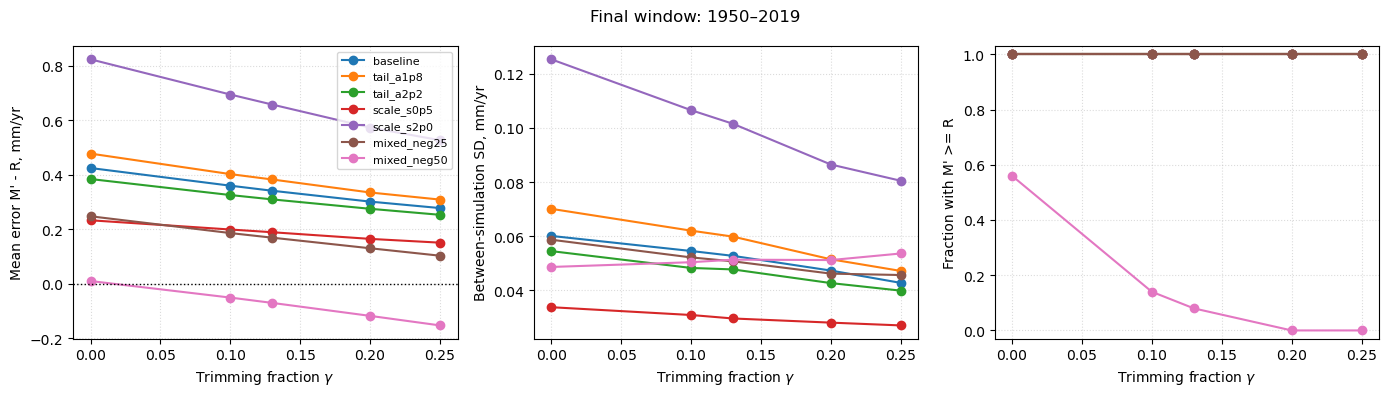

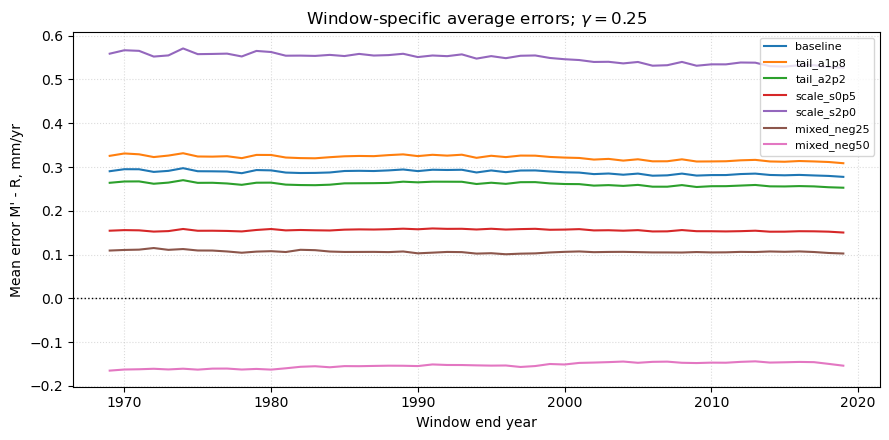

Summary exports: C:\Users\User\work\IPGP\Climate\bin\validation_sensitivity_results\summary_20261123_151755_881117100


In [19]:
if not window_table.empty:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    export_id = time.strftime("%Y%m%d_%H%M%S") + "_" + str(time.time_ns() % 1000000000)
    export_dir = OUTPUT_DIR / ("summary_" + export_id)
    export_dir.mkdir()
    window_table.to_csv(export_dir / "all_windows.csv", index=False)
    final_table.to_csv(export_dir / "final_window.csv", index=False)
    trajectory_table.to_csv(export_dir / "trajectory_summary.csv", index=False)
    scenario_table.to_csv(export_dir / "scenario_definitions.csv", index=False)
    metadata_export = {name: state["metadata"] for name, state in results.items()}
    (export_dir / "experiment_metadata.json").write_text(
        json.dumps(metadata_export, indent=2), encoding="utf-8")
    fig_final = plot_final_comparison(window_table)
    fig_final.savefig(export_dir / "final_window_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()
    if np.any(np.isclose(window_table["gamma"], .25)):
        fig_windows = plot_window_means(window_table, gamma=.25)
        fig_windows.savefig(export_dir / "window_mean_errors.png", dpi=180, bbox_inches="tight")
        plt.show()
    print("Summary exports:", export_dir.resolve())
else:
    print("Run the summary cell after results become available.")


In [39]:
def plot_final_comparison(window_table):
    final = window_table[
        window_table["end_year"] == window_table["end_year"].max()
    ]

    labels = {
        "baseline": "Baseline",
        "tail_a1p8": r"$a=1.8$",
        "tail_a2p2": r"$a=2.2$",
        "scale_s0p5": r"$s=0.5$ mm/yr",
        "scale_s2p0": r"$s=2$ mm/yr",
        "mixed_neg25": "25% negative contributions",
        "mixed_neg50": "50% negative contributions",
    }

    fig, axes = plt.subplots(
        1, 3, figsize=(12, 4.3), layout="constrained"
    )

    for name, rows in final.groupby("scenario", sort=False):
        rows = rows.sort_values("gamma")
        x = rows["gamma"].to_numpy()
        label = labels.get(name, name)

        for ax, column in zip(
            axes,
            ["mean_error", "sd_error", "fraction_ge_R"],
        ):
            ax.plot(
                x,
                rows[column],
                marker="o",
                linewidth=1.5,
                markersize=5,
                label=label,
            )

    axes[0].axhline(0, color="black", linestyle=":", linewidth=1)
    axes[0].set_ylabel(r"Mean error $M'-R$, mm/yr")
    axes[1].set_ylabel("Between-simulation SD, mm/yr")
    axes[2].set_ylabel(r"Fraction with $M'\geq R$")
    axes[2].set_ylim(-0.03, 1.07)

    for ax, panel in zip(axes, ["(a)", "(b)", "(c)"]):
        ax.set_xlabel(r"Trimming fraction $\gamma$", fontsize=11)
        ax.grid(linestyle=":", alpha=0.45)
        ax.text(
            0.03, 0.90, panel,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=12,
            fontweight="bold",
        )

    # The open central-right region of panel (c).
    axes[2].legend(
        loc="center right",
        fontsize=10,
        frameon=True,
        framealpha=0.95,
    )

    first = final.iloc[0]
    fig.suptitle(
        f"Final window: "
        f"{int(first['start_year'])}–{int(first['end_year'])}"
    )

    return fig

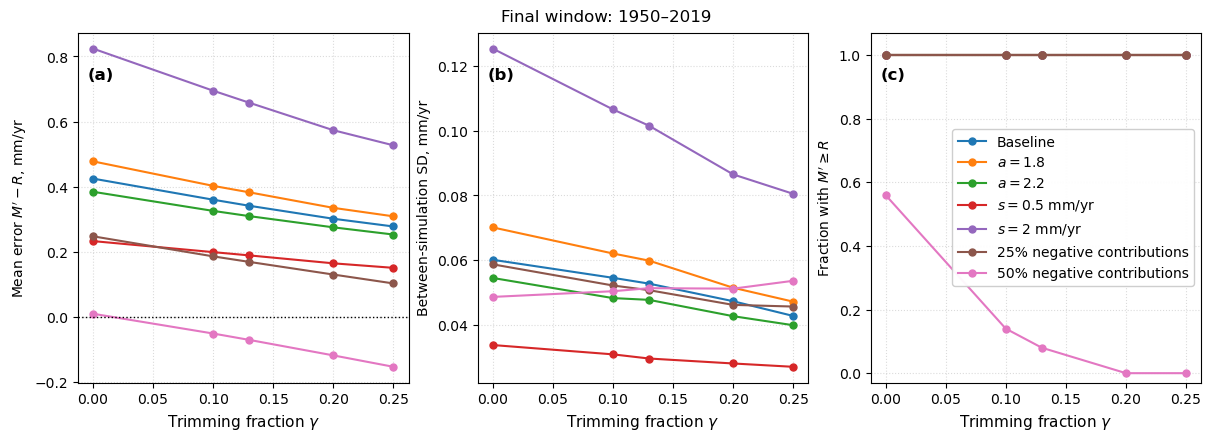

In [40]:
fig = plot_final_comparison(window_table)
plt.show()

In [41]:
fig.savefig("validation_sensitivity_results/synthetic_validation.jpg", dpi=600, bbox_inches="tight")

## 14. Interpreting the sensitivity results

First compare $a=1.8,2.0,2.2$ at fixed $s=1$, then $s=0.5,1,2$ at fixed $a=2$. State the known $R$, increment noise, sign assumption, completeness and selection rule alongside any conclusions. The baseline's exclusively positive contributions favor an upward displacement. Mixed-sign runs investigate a different assumption about station heterogeneity.

The positive-only full-record experiment previously produced a final-window mean error of $0.2854$ mm/yr and SD $0.0428$ mm/yr at $\gamma=0.25$ across 200 runs. This is a **historical check value from the supplied notebook**, not output generated by this new notebook. Full arrays can be reused only through the explicit import above.

The exponent/scale tests examine distributional sensitivity; they do not independently calibrate the noise magnitude or resolve the annual-residual autocorrelation and multiple-testing questions. Keep those analyses distinct in the revision.

**Next decisions after inspection:** whether an additional sign-balance scenario is useful, whether the noise scale needs its own sensitivity analysis, and when to add spatial correlations. This notebook retains independent increments throughout.
